# MICS Procurement Analysis (Path B)
**BlinkHub Procurement Innovation Challenge** · David Ramokgola

This notebook answers the seven investigation questions in the case study, then extends the analysis
with a synthetic year of data.

| Part | Data | Status |
|---|---|---|
| **A. Case-study sample** | The 8 suppliers, 12 POs and 8 invoices from section 6, **exactly as printed** | Real assessment data (fictional company) |
| **B. Synthetic year** | ~450 suppliers, ~R85m, generated by `backend/seed/synthetic.py` | **Demonstration only.** It shows how the analysis scales. It is not MICS's performance |

Both parts are reproduced automatically in the BlinkHub platform: the dbt models in `analytics/dbt` rebuild the
same measures every night, and Power BI reads them. That covers the brief's *"demonstrate how your analysis could
be automated or incorporated into BlinkHub"*.

**Approach:** load → clean and validate → answer each question with numbers and a chart → findings →
recommendations → assumptions and limitations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from pathlib import Path

RAW, SYN = Path("data/raw"), Path("data/synthetic")

# Chart style: validated categorical palette (slot 1 blue, slot 2 orange), neutral ink for text.
LARGE, SMME, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})
rand = lambda x: f"R{x:,.0f}"
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Part A: the case-study sample

### 1. Load the raw data, as printed

In [2]:
suppliers_raw = pd.read_csv(RAW / "supplier_register.csv")
pos_raw = pd.read_csv(RAW / "purchase_orders.csv")
inv_raw = pd.read_csv(RAW / "invoices.csv")
display(suppliers_raw, pos_raw.head(3), inv_raw.head(3))
print(pos_raw.dtypes["Amount"], "<- amounts are text, so they can't be summed yet")

,Supplier,Province,Supplier Type,B-BBEE Level,Status
0,Ubuntu Cleaning,Gauteng,SMME,Level 1,Active
1,Prime Facilities,Gauteng,Large Enterprise,Level 2,Active
2,Thuto Supplies,Limpopo,SMME,Level 1,Active
3,Metro Logistics,Gauteng,Large Enterprise,Level 4,Active
4,Khula Electrical,Mpumalanga,SMME,Level 2,Active
5,Rapid Transport,KZN,SMME,Level 1,Active
6,Apex Infrastructure,Gauteng,Large Enterprise,Level 3,Active
7,Sisonke Trading,Limpopo,SMME,Level 1,Inactive


,PO Number,Supplier,Category,Department,Amount
0,PO001,Ubuntu Cleaning,Cleaning,Facilities,"R85,000"
1,PO002,Prime Facilities,Cleaning,Facilities,"R450,000"
2,PO003,Thuto Supplies,Stationery,Administration,"R35,000"


,Invoice,Supplier,Amount,Days Outstanding,Status
0,INV001,Ubuntu Cleaning,"R85,000",15,Paid
1,INV002,Thuto Supplies,"R35,000",42,Outstanding
2,INV003,Metro Logistics,"R620,000",65,Outstanding


str <- amounts are text, so they can't be summed yet


### 2. Clean and validate

Six data-quality checks, each one a rule that the dbt tests now enforce automatically.

In [3]:
def to_rand(s: pd.Series) -> pd.Series:
    return s.str.replace("R", "", regex=False).str.replace(",", "", regex=False).astype(float)

PROVINCE = {"KZN": "KwaZulu-Natal"}

suppliers = (suppliers_raw.rename(columns=str.lower).rename(columns={"supplier type": "type", "b-bbee level": "bbbee"})
             .assign(province=lambda d: d.province.replace(PROVINCE).str.strip(),
                     is_smme=lambda d: d.type.eq("SMME"),
                     bbbee=lambda d: d.bbbee.str.extract(r"(\d)").astype(int)))
pos = pos_raw.rename(columns=str.lower).rename(columns={"po number": "po"}).assign(amount=lambda d: to_rand(d.amount))
inv = (inv_raw.rename(columns=str.lower).rename(columns={"days outstanding": "days"})
       .assign(amount=lambda d: to_rand(d.amount)))

checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "ISSUE", "detail": detail})

check("Amounts parsed to numbers", pos.amount.notna().all() and inv.amount.notna().all(),
      "'R85,000' -> 85000.0")
check("Province names standardised", "KZN" not in set(suppliers.province), "KZN -> KwaZulu-Natal")
unknown = (set(pos.supplier) | set(inv.supplier)) - set(suppliers.supplier)
check("Every PO/invoice supplier exists in the register", not unknown, ", ".join(unknown) or "all 8 match")
check("No duplicate PO numbers", pos.po.is_unique)
check("Invoices reference a PO", False, "No invoice carries a PO number, so 3-way matching is impossible")
dept_by_cat = pos.groupby("category").department.agg(lambda s: s.mode()[0])
odd = pos[pos.department != pos.category.map(dept_by_cat)]
check("Category charged to its usual department", odd.empty,
      "; ".join(f"{r.po}: {r.category} charged to {r.department}" for r in odd.itertuples()))
pd.DataFrame(checks)

,check,result,detail
0,Amounts parsed to numbers,PASS,"'R85,000' -> 85000.0"
1,Province names standardised,PASS,KZN -> KwaZulu-Natal
2,Every PO/invoice supplier exists in the register,PASS,all 8 match
3,No duplicate PO numbers,PASS,
4,Invoices reference a PO,ISSUE,"No invoice carries a PO number, so 3-way match..."
5,Category charged to its usual department,ISSUE,PO009: Cleaning charged to Operations


**Data-quality findings:**
- **No invoice carries a PO reference.** This is the root cause behind several problems, because no system can match an invoice to an order or a delivery.
- **PO009** books Prime Facilities' *cleaning* to **Operations**, while every other cleaning PO goes to Facilities. It could be a coding error or a budget workaround; it needs confirming.
- Both are now enforced in BlinkHub. Invoices without a PO go to `EXCEPTION`, and dbt tests stop bad data from reaching dashboards.

### Q1. Which suppliers receive the most money?

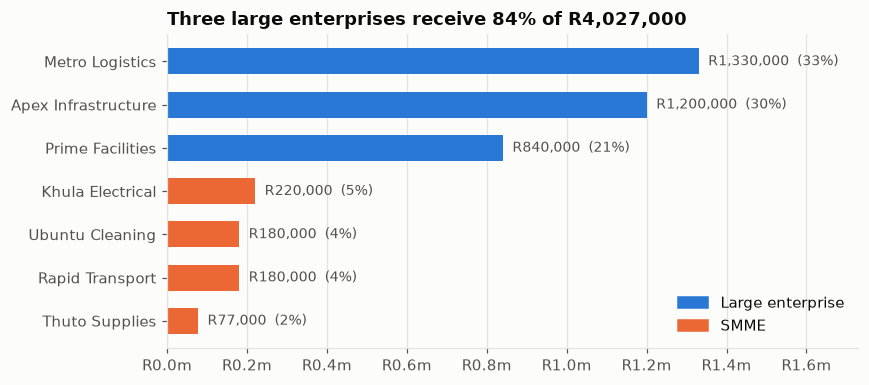

,supplier,type,bbbee,spend,share,cumulative
2,Metro Logistics,Large Enterprise,4,"1,330,000.00",0.33,0.33
0,Apex Infrastructure,Large Enterprise,3,"1,200,000.00",0.30,0.63
3,Prime Facilities,Large Enterprise,2,"840,000.00",0.21,0.84
1,Khula Electrical,SMME,2,"220,000.00",0.05,0.89
4,Rapid Transport,SMME,1,"180,000.00",0.04,0.94
6,Ubuntu Cleaning,SMME,1,"180,000.00",0.04,0.98
5,Thuto Supplies,SMME,1,"77,000.00",0.02,1.00


In [4]:
spend = (pos.groupby("supplier").amount.sum().rename("spend").reset_index()
         .merge(suppliers[["supplier", "type", "is_smme", "province", "bbbee"]], on="supplier")
         .sort_values("spend", ascending=False))
total = spend.spend.sum()
spend["share"] = spend.spend / total
spend["cumulative"] = spend.share.cumsum()

fig, ax = plt.subplots(figsize=(8, 3.6))
d = spend.sort_values("spend")
bars = ax.barh(d.supplier, d.spend, color=[SMME if s else LARGE for s in d.is_smme], height=0.6)
for b, (v, sh) in zip(bars, zip(d.spend, d.share)):
    ax.text(b.get_width() + total * 0.006, b.get_y() + b.get_height() / 2, f"{rand(v)}  ({sh:.0%})",
            va="center", color=MUTED, fontsize=9)
ax.set_xlim(0, d.spend.max() * 1.3)
ax.xaxis.set_major_formatter(lambda x, _: f"R{x/1e6:.1f}m")
ax.grid(axis="y", visible=False)
ax.set_title(f"Three large enterprises receive {spend[~spend.is_smme].share.sum():.0%} of {rand(total)}")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LARGE), plt.Rectangle((0, 0), 1, 1, color=SMME)],
          labels=["Large enterprise", "SMME"], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
spend[["supplier", "type", "bbbee", "spend", "share", "cumulative"]]

**Finding 1: concentration.** Metro Logistics (33%), Apex Infrastructure (30%) and Prime Facilities (21%) receive
**84% of spend**. The largest recipient, Metro, has the **weakest B-BBEE level (4)**, so the biggest share of spend earns
the least recognition on MICS's preferential-procurement scorecard.

### Q2. What share of spend goes to SMMEs?

In [5]:
smme_share = spend.loc[spend.is_smme, "spend"].sum() / total
by_prov = (spend.groupby("province").agg(spend=("spend", "sum")).assign(share=lambda d: d.spend / total)
           .sort_values("spend", ascending=False))
recognition = {1: 1.35, 2: 1.25, 3: 1.10, 4: 1.00}
recognised = (spend.spend * spend.bbbee.map(recognition)).sum()
print(f"SMME share of spend:            {smme_share:.1%}  ({rand(spend.loc[spend.is_smme,'spend'].sum())})")
print(f"B-BBEE recognised spend:         {rand(recognised)}  ({recognised/total:.0%} of actual spend)")
print(f"Inactive SMME with no spend:     Sisonke Trading (Limpopo)")
by_prov

SMME share of spend:            16.3%  (R657,000)
B-BBEE recognised spend:         R4,564,950  (113% of actual spend)
Inactive SMME with no spend:     Sisonke Trading (Limpopo)


,spend,share
province,,
Gauteng,"3,550,000.00",0.88
Mpumalanga,"220,000.00",0.05
KwaZulu-Natal,"180,000.00",0.04
Limpopo,"77,000.00",0.02


**Finding 2: SMMEs receive 16.3%, and spend is concentrated in Gauteng (88%).** Limpopo, Mpumalanga and KwaZulu-Natal
together receive under 12%. **Sisonke Trading**, a Level 1 SMME in Limpopo, is registered but has received nothing. That points to
an access problem (Problem 2), not a lack of SMME capacity.

### Q3. Are there repeated transactions?

In [6]:
rep = pos[pos.supplier.duplicated(keep=False)].sort_values(["supplier", "po"])
display(rep)
cleaning = pos[pos.category.eq("Cleaning")].merge(suppliers[["supplier", "type"]], on="supplier")
cleaning.groupby(["supplier", "type"]).amount.agg(["count", "mean", "sum"])

,po,supplier,category,department,amount
4,PO005,Khula Electrical,Maintenance,Infrastructure,"95,000.00"
11,PO012,Khula Electrical,Maintenance,Infrastructure,"125,000.00"
3,PO004,Metro Logistics,Transport,Operations,"620,000.00"
10,PO011,Metro Logistics,Transport,Operations,"710,000.00"
1,PO002,Prime Facilities,Cleaning,Facilities,"450,000.00"
8,PO009,Prime Facilities,Cleaning,Operations,"390,000.00"
2,PO003,Thuto Supplies,Stationery,Administration,"35,000.00"
9,PO010,Thuto Supplies,Stationery,Administration,"42,000.00"
0,PO001,Ubuntu Cleaning,Cleaning,Facilities,"85,000.00"
7,PO008,Ubuntu Cleaning,Cleaning,Facilities,"95,000.00"


,,count,mean,sum
supplier,type,,,
Prime Facilities,Large Enterprise,2,"420,000.00","840,000.00"
Ubuntu Cleaning,SMME,2,"90,000.00","180,000.00"


**Finding 3: five suppliers have repeat POs** (Ubuntu, Prime, Thuto, Metro, Khula). Repeats are normal for
ongoing services, but the cleaning category stands out:
- **Prime Facilities' cleaning POs average R420,000; Ubuntu Cleaning (SMME, Level 1) averages R90,000.** That's a gap of about 4.7×.
- The scope may differ (sites, frequency), so this **needs a like-for-like scope comparison**. If the scopes are similar, moving cleaning work to Ubuntu or other SMMEs is a **cost saving and a B-BBEE gain at the same time**.

### Q4. Which invoices require attention?

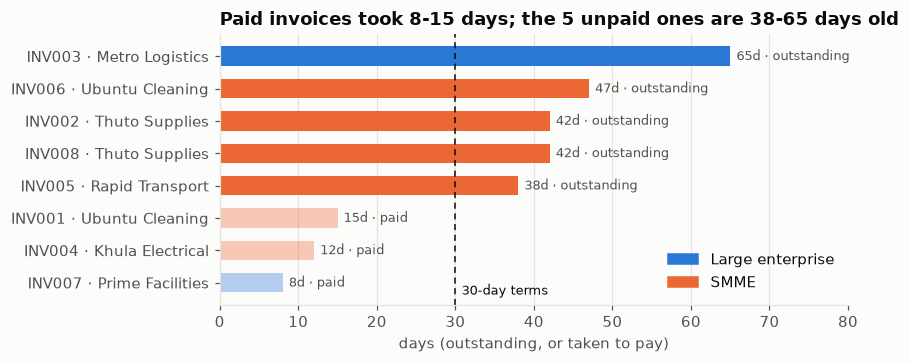

Outstanding past 30 days: 5 invoices, R955,000


,invoice,supplier,amount,days,is_smme
2,INV003,Metro Logistics,"620,000.00",65,False
5,INV006,Ubuntu Cleaning,"85,000.00",47,True
1,INV002,Thuto Supplies,"35,000.00",42,True
7,INV008,Thuto Supplies,"35,000.00",42,True
4,INV005,Rapid Transport,"180,000.00",38,True


In [7]:
inv2 = inv.merge(suppliers[["supplier", "is_smme"]], on="supplier")
inv2["over_30"] = inv2.days > 30
attention = inv2[inv2.status.eq("Outstanding")].sort_values("days", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.4))
d = inv2.sort_values("days")
# paid invoices drawn lighter, outstanding ones solid
ax.barh(d.invoice + " · " + d.supplier, d.days, height=0.6,
        color=[to_rgba(SMME if s else LARGE, 1.0 if st == "Outstanding" else 0.35)
               for s, st in zip(d.is_smme, d.status)])
for i, r in enumerate(d.itertuples()):
    ax.text(r.days + 0.8, i, f"{r.days}d · {r.status.lower()}", va="center", fontsize=8.5, color=MUTED)
ax.axvline(30, color=INK, lw=1, ls=(0, (4, 3)))
ax.text(30.8, -0.25, "30-day terms", fontsize=8.5, color=INK, va="center")
ax.set_xlim(0, 80); ax.grid(axis="y", visible=False); ax.set_xlabel("days (outstanding, or taken to pay)")
ax.set_title("Paid invoices took 8-15 days; the 5 unpaid ones are 38-65 days old")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LARGE), plt.Rectangle((0, 0), 1, 1, color=SMME)],
          labels=["Large enterprise", "SMME"], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
print(f"Outstanding past 30 days: {len(attention)} invoices, {rand(attention.amount.sum())}")
attention[["invoice", "supplier", "amount", "days", "is_smme"]]

**Finding 4: R955,000 is unpaid past the 30-day terms, across 5 invoices (every outstanding invoice).** Metro's R620,000 is the
oldest (65 days). Three of the five are **SMMEs** (Rapid Transport, Ubuntu Cleaning, Thuto), the suppliers least able to absorb
late payment, as in the case study's 75-day cleaning company. Note that *no outstanding invoice has an accountable approver
recorded*; this is the gap BlinkHub's routing closes.

### Q5. Are there possible duplicate invoices?

In [8]:
dups = inv2[inv2.duplicated(["supplier", "amount"], keep=False)].sort_values(["supplier", "invoice"])
dups[["invoice", "supplier", "amount", "days", "status"]]

,invoice,supplier,amount,days,status
1,INV002,Thuto Supplies,"35,000.00",42,Outstanding
7,INV008,Thuto Supplies,"35,000.00",42,Outstanding
0,INV001,Ubuntu Cleaning,"85,000.00",15,Paid
5,INV006,Ubuntu Cleaning,"85,000.00",47,Outstanding


**Finding 5: two possible duplicates, totalling R120,000 at risk.**
- **INV002 and INV008 (Thuto, R35,000, both 42 days, both unpaid).** Same supplier, amount and age, which looks like one invoice entered twice. Thuto's two POs are R35,000 and R42,000, so only one R35,000 invoice is expected.
- **INV006 (Ubuntu, R85,000, unpaid).** Its amount matches **PO001**, which INV001 has **already paid**. Ubuntu's other PO is R95,000. INV006 is either a duplicate claim for PO001 or a wrongly priced invoice for PO008.

*These are risk indicators, not proof of fraud.* The BlinkHub risk engine raises both as flags (`DUP_INVOICE`) with this
evidence attached, for an investigator to confirm or dismiss.

### Q6. What additional data should be requested?

| Data | Why it's needed |
|---|---|
| **PO reference on every invoice** | Enables 3-way matching and automatic duplicate detection |
| **Invoice, received, approval and payment dates** | "Days outstanding" alone can't show where delays happen |
| **Goods-received notes (GRNs)** | Proof of delivery before payment (Problem 6) |
| **Approver and approval-log history** | Accountability for stuck invoices; segregation-of-duties checks |
| **Contracts (value, start/end, scope)** | Contract expiry tracking (Problem 5); the like-for-like cleaning comparison |
| **PO line items (item, quantity, unit price)** | Price variance for the same item across regions and suppliers |
| **Quotations per opportunity** | Detect unusually similar quotes; measure competition |
| **Bank-detail change history** | Detect payment redirection |
| **Compliance documents with expiry dates** | Tax clearance and B-BBEE validity at the time of payment |
| **Department budgets** | Budget burn and overspending alerts |

### Q7. What should management see on a dashboard?

Built as the Power BI report (`powerbi/`) and the BlinkHub web dashboard:
1. **Spend overview:** total spend, by department, category, supplier and province, and the trend.
2. **Transformation:** SMME share and B-BBEE recognised spend against target, plus provincial reach.
3. **Payment performance:** invoice ageing (0-30/31-60/61-90/90+), % paid within terms, SMME vs large days-to-pay, invoices without an owner.
4. **Concentration:** top-supplier share and HHI per category, with the Pareto (ABC) view.
5. **Risk:** open flags by rule and severity, value under review, investigation status.
6. **Supplier performance:** scorecards (delivery, accuracy, compliance, risk, price).

## Part B: synthetic demonstration year

> **Synthetic data, for demonstration only.** It's generated with a fixed seed to show how the analysis behaves at the brief's
> scale (~450 suppliers, ~R85m). The payment gap between SMMEs and large suppliers was *built in deliberately* to mirror the
> case-study sample. **None of these figures are MICS's real performance.**

,supplier_type,invoices_paid,avg_days_to_pay,pct_within_30_days
0,SMME,1080,33.40,0.42
1,Large enterprise,1204,15.60,0.94


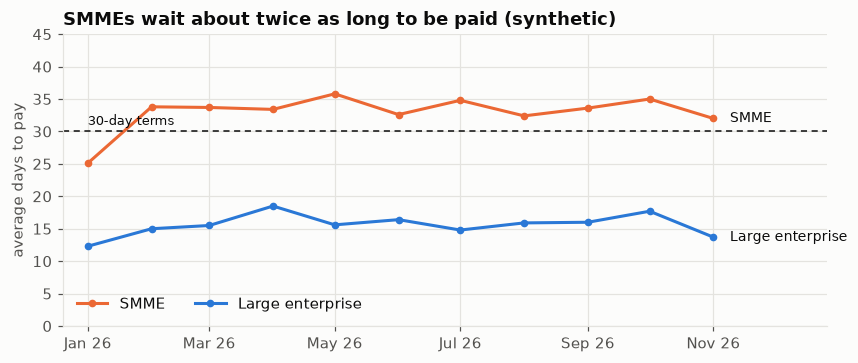

In [9]:
pay = pd.read_csv(SYN / "payment_by_type.csv")
months = pd.read_csv(SYN / "monthly_kpis.csv", parse_dates=["month"])
display(pay)

fig, ax = plt.subplots(figsize=(8, 3.4))
m = months.dropna(subset=["avg_days_to_pay_smme"]).iloc[1:]  # first month is a partial ramp-up
for col, colour, label in [("avg_days_to_pay_smme", SMME, "SMME"), ("avg_days_to_pay_large", LARGE, "Large enterprise")]:
    ax.plot(m.month, m[col], color=colour, lw=2, marker="o", ms=4)
    ax.text(m.month.iloc[-1] + pd.Timedelta(days=8), m[col].iloc[-1], label, color=INK, va="center", fontsize=9)
ax.axhline(30, color=INK, lw=1, ls=(0, (4, 3))); ax.text(m.month.iloc[0], 31, "30-day terms", fontsize=8.5)
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_xlim(m.month.iloc[0] - pd.Timedelta(days=12), m.month.iloc[-1] + pd.Timedelta(days=55))
ax.set_ylim(0, 45); ax.set_ylabel("average days to pay")
ax.set_title("SMMEs wait about twice as long to be paid (synthetic)")
ax.legend(["SMME", "Large enterprise"], frameon=False, loc="lower left", ncol=2)
plt.tight_layout(); plt.show()

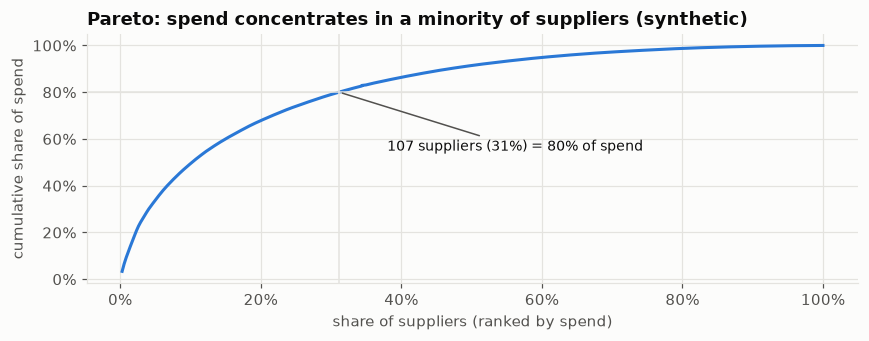

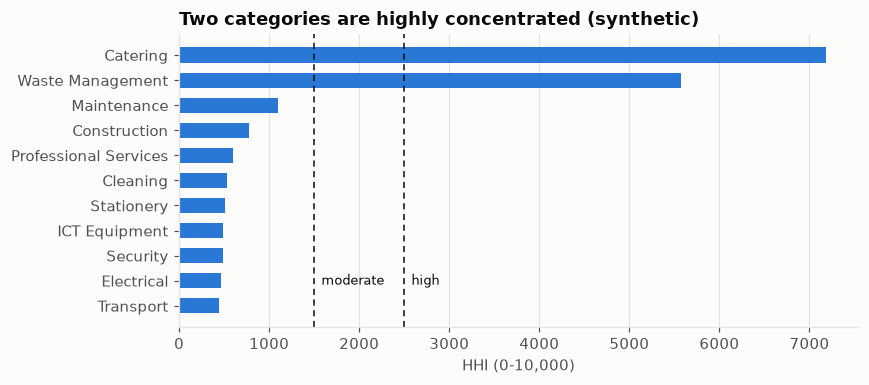

,category_name,suppliers,hhi,top_supplier_share,concentration_band
10,Transport,46,445,0.10,Competitive
9,Electrical,49,468,0.10,Competitive
8,Security,43,487,0.11,Competitive
7,ICT Equipment,41,488,0.09,Competitive
6,Stationery,47,510,0.11,Competitive
5,Cleaning,42,530,0.12,Competitive
4,Professional Services,36,601,0.15,Competitive
3,Construction,34,776,0.14,Competitive
2,Maintenance,38,1094,0.26,Competitive
1,Waste Management,19,5579,0.74,Highly concentrated


In [10]:
sup = pd.read_csv(SYN / "supplier_spend.csv")
fig, ax = plt.subplots(figsize=(8, 3.2))
x = sup.spend_rank / len(sup)
ax.plot(x, sup.cumulative_share, color=LARGE, lw=2)
a = sup[sup.abc_class == "A"]
ax.axhline(0.8, color=GRID, lw=1); ax.axvline(len(a) / len(sup), color=GRID, lw=1)
ax.annotate(f"{len(a)} suppliers ({len(a)/len(sup):.0%}) = 80% of spend", (len(a) / len(sup), 0.8),
            xytext=(0.38, 0.55), fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("share of suppliers (ranked by spend)"); ax.set_ylabel("cumulative share of spend")
ax.set_title("Pareto: spend concentrates in a minority of suppliers (synthetic)")
plt.tight_layout(); plt.show()

conc = pd.read_csv(SYN / "category_concentration.csv").sort_values("hhi")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(conc.category_name, conc.hhi, color=LARGE, height=0.6)
for v, label in [(1500, "moderate"), (2500, "high")]:
    ax.axvline(v, color=INK, lw=1, ls=(0, (4, 3))); ax.text(v + 80, 1, label, fontsize=8.5, va="center")
ax.grid(axis="y", visible=False); ax.set_xlabel("HHI (0-10,000)")
ax.set_title("Two categories are highly concentrated (synthetic)")
plt.tight_layout(); plt.show()
conc[["category_name", "suppliers", "hhi", "top_supplier_share", "concentration_band"]]

In [11]:
flags = pd.read_csv(SYN / "risk_flags.csv")
flags.groupby("rule_name").agg(flags=("flags", "sum"), value_at_risk=("value_at_risk", "sum")).sort_values("flags", ascending=False)

,flags,value_at_risk
rule_name,,
Payments just below an approval limit,29,"1,379,949.36"
Possible duplicate invoice,25,"892,119.55"
Unusual invoice (machine learning),24,"10,686,107.18"
Paid without delivery evidence,24,"591,315.45"
Paid while non-compliant,15,0.00
Bank details changed shortly before payment,10,"191,507.05"
Unusually similar quotations,8,0.00
Supplier concentration in a category,2,0.00


**Synthetic-year observations** (they illustrate what the platform surfaces at scale; they are not MICS findings):
- Large suppliers are paid within 30 days ~94% of the time, against ~43% for SMMEs.
- About 30% of suppliers make up 80% of spend (ABC class A), which is the normal Pareto shape. Catering and Waste Management are dominated by single suppliers (HHI above 5,000).
- The risk engine raises flags across all eight rules. Against the planted answer key it achieves **99.2% recall and 89.8% precision** (`GET /api/v1/risk/evaluation`).

## Findings (case-study sample)

1. **Concentration:** three large enterprises receive 84% of the R4.03m; the largest (Metro) has the weakest B-BBEE level.
2. **SMME share is 16.3%**, and 88% of spend stays in Gauteng. A registered Limpopo SMME (Sisonke) has received nothing.
3. **Payment inequity:** paid invoices took 8-15 days, while five unpaid invoices (R955k, three of them SMMEs) are 38-65 days old.
4. **Two likely duplicates (R120k at risk):** Thuto INV002/INV008, and Ubuntu INV006 against an already-paid PO.
5. **The cleaning price gap** (Prime about 4.7× Ubuntu per PO) needs a scope comparison; it's a potential saving and SMME opportunity.
6. **Process gaps:** no invoice has a PO reference or an accountable approver, and PO009 is miscoded to Operations.

## Recommendations

| # | Action | Addresses | Expected impact |
|---|---|---|---|
| 1 | **Hold INV008 and INV006** until verified; recover if already processed | Finding 4 | Avoid paying up to R120,000 twice |
| 2 | **Make the PO number mandatory** on invoices (supplier portal) and 3-way-match before approval | 3, 4, 6 | Automatic duplicate and over-billing prevention |
| 3 | **Route every invoice to a named approver** with 20/25/30-day escalation; **prioritise SMMEs** | 3 | Pay within terms; protect SMME cash flow |
| 4 | **Clear the R955k backlog this week**, Metro's 65-day invoice first by value and the SMMEs first by impact | 3 | Supplier relationships, reputational risk |
| 5 | **Benchmark cleaning scopes** (Prime vs Ubuntu) and run an SMME set-aside for comparable work | 1, 2, 5 | Cost saving plus higher SMME share and B-BBEE recognition |
| 6 | **Set an SMME spend target** (e.g. 30%) with **provincial opportunities**, and re-activate suppliers like Sisonke | 2 | Wider participation beyond Gauteng |
| 7 | **Correct PO009's coding** and add department/category validation | 6 | Reliable departmental reporting |
| 8 | **Run the risk engine and dashboards on the full year of data** (request list in Q6) | all | Replace manual monthly reports |

## Assumptions and limitations

- The sample is small (8 suppliers, 12 POs, 8 invoices); the findings are **indicative** and need confirming on full data.
- "Spend" means **committed PO value**. Invoices carry no PO reference, so they can't be linked to POs with certainty.
- "Days outstanding" is taken as given. For paid invoices it's read as the days taken to pay.
- The 30-day payment standard is assumed (common practice and the public-sector norm). MICS's actual terms weren't given.
- The B-BBEE recognition levels follow the Codes of Good Practice table (Level 1 = 135% ... Level 4 = 100%).
- Part B is **synthetic**, and its patterns are partly built in by design. It demonstrates method and scale, not facts about MICS.